# GREPO dataset preparation and exploration

**CS224W · Project Milestone 1 · Notebook 1**

Start with **csvkit**. Run Sections 1–6 in order to download a small real GREPO subset, inspect sample issues, measure candidate coverage, and produce a PyTorch Geometric dataset. Section 7 optionally exports it. The GraphSAGE check uses a supported GPU when available and otherwise runs on CPU.

**Verified default run.** The download was 4.62 MB. The csvkit release graph contained 26,385 historical nodes and 153,656 edges. The notebook built 55 training and 13 test issue graphs, completed a GraphSAGE forward pass, and reloaded an exported example. With one-hop expansion, 56 of 68 labeled issues had at least one gold node in the candidates, and 24 had the full gold set. These are candidate coverage results for csvkit.

Reusable transformations live in `grepo_localization.exploration`, where they have explicit inputs, return values, documentation, and unit tests. The notebook keeps only display-specific functions and short orchestration cells. Edit the settings in Section 1 to change repositories or graph options.

| GREPO file | What it gives us |
|---|---|
| Timed PyG graph | Versioned code nodes, directed edges, relation IDs, and node lifetimes |
| Anchor JSON | Issue time, issue-derived seed nodes, and patch-derived gold node IDs |
| Rewriter JSON | Search queries derived from an issue |
| Node embeddings (optional) | Precomputed node content features |

[GREPO dataset on ModelScope](https://modelscope.cn/datasets/qingpingmomo/Grepo) · [Official code](https://github.com/qingpingmo/GREPO) · [Paper](https://arxiv.org/abs/2602.13921)

## 1. Set up the environment

Install the shared package using the local or Colab command below. In Colab, keep the PyTorch build supplied by your runtime so CUDA support stays available. The smoke test uses CUDA when available and otherwise uses CPU. It does not select Apple MPS automatically because support depends on the installed PyTorch and PyTorch Geometric versions, and unsupported operations can terminate the notebook kernel. GREPO's historical graphs use pickle serialization. Enable loading only for artifacts you trust, in an isolated environment.

In [1]:
# Local Jupyter: install from the repository root with pip install -e '.[notebook]'.
# Colab: uncomment this line and replace OWNER/REPO with the public GitHub repository.
# %pip install "grepo-localization[notebook] @ git+https://github.com/OWNER/REPO.git"
# Colab supplies PyTorch. Keep its installed build to retain GPU support.

In [2]:
from collections.abc import Mapping, Sequence
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch_geometric.loader import DataLoader

REPOS = ["csvkit"]  # Try one repo first. Section 2 lists the available names.
ROOT = Path("grepo_workspace")
REVISION = "master"
HOPS = 1
USE_CONTENT_EMBEDDINGS = False  # Adds about 865 MB for csvkit.
TRUST_OFFICIAL_PYG_FILES = True  # Set True after reviewing Section 1.

API = "https://modelscope.cn/api/v1/datasets/qingpingmomo/Grepo/repo"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"GraphSAGE device: {device}")

GraphSAGE device: cpu


.venv/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
.venv/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Set up the GREPO corpus

The full ModelScope release includes large historical graphs and embeddings. This notebook fetches only the files selected above. It verifies file size and SHA-256 against the release manifest and reuses verified files on reruns. The manifest check verifies transfer integrity. The paper describes 86 repositories. The inspected release inventory had 85 with all three default inputs.

Use `corpus.issue_refs(repo)` to list issues, `corpus.issue(ref)` for search queries and starting anchors, and `corpus.repository_graph(repo)` for the historical graph. `corpus.nodes(repo, ids)` adds names and historical source text. `corpus.gold(ref)` gives the answer key separately.

The setup below prepares the selected repositories' graph and metadata files. The corpus loads original reports and source code on demand, so the training dataset can build structural graphs without those downloads.

### Plan the download

In [3]:
from grepo_localization.corpus import release_manifest, repo_paths

In [4]:
manifest = release_manifest(API, REVISION)

required = ["graph", "anchors", "queries"]
if USE_CONTENT_EMBEDDINGS:
    required += ["embeddings", "embedding_index"]

available_repos = sorted(
    path.split("/")[-2] for path in manifest if path.endswith("/anchor_node.json")
    and all(repo_paths(path.split("/")[-2])[kind] in manifest for kind in required)
)
print(f"{len(available_repos)} repositories have the selected inputs.")
print(", ".join(available_repos))
if not REPOS or set(REPOS) - set(available_repos):
    raise ValueError("Set REPOS to one or more names from the list above.")
if len(set(REPOS)) != len(REPOS):
    raise ValueError("List each repository once.")

selected_paths = {repo: {kind: repo_paths(repo)[kind] for kind in required}
                  for repo in REPOS}
download_plan = pd.DataFrame([
    dict(repo=repo, artifact=kind, MB=round(manifest[path]["Size"] / 1e6, 2))
    for repo, paths in selected_paths.items() for kind, path in paths.items()
])
display(download_plan)
print(f"Full release inventory: {sum(item['Size'] for item in manifest.values()) / 1e12:.2f} TB")

85 repositories have the selected inputs.
Cirq, Flexget, PyBaMM, PyPSA, Radicale, Solaar, WeasyPrint, aider, aiogram, ansible-lint, arviz, astroid, astropy, attrs, babel, beancount, beets, briefcase, cfn-lint, checkov, conan, conda, crawlee-python, cryptography, csvkit, datasets, dspy, dvc, dynaconf, falcon, faststream, feature_engine, filesystem_spec, flask, fonttools, geopandas, haystack, icloud_photos_downloader, instructlab, ipython, jax, jupyter-ai, kedro, keras, litellm, llama-stack, llama_deploy, marshmallow, matplotlib, mesa, mypy, networkx, ntc-templates, openai-agents-python, patroni, pipenv, poetry, privacyidea, pvlib-python, pydicom, pylint, pyomo, python, python-control, python-telegram-bot, pyvista, qtile, scipy, scrapy-splash, segmentation_models.pytorch, shapely, smolagents, sphinx, sqlfluff, streamlink, tablib, torchtune, tox, transformers, transitions, twine, urllib3, wemake-python-styleguide, xarray, yt-dlp


,repo,artifact,MB
0,csvkit,graph,4.43
1,csvkit,anchors,0.06
2,csvkit,queries,0.13


Full release inventory: 1.36 TB


### Download and verify the selected files

In [5]:
from grepo_localization.corpus import download_repositories

### Define the corpus interface

In [6]:
from grepo_localization.corpus import GrepoCorpus, IssueRecord, IssueRef, NodeRecord

In [7]:
local_files = download_repositories(selected_paths, manifest, ROOT, API, REVISION)

corpus = GrepoCorpus(manifest, ROOT, API, REVISION, trust_graph_files=TRUST_OFFICIAL_PYG_FILES)

csvkit · graph
csvkit · anchors
csvkit · queries


## 3. Inspect the raw graph and example issues

GREPO represents a repository as a map of its code. A **node** is one piece of code or a directory. An **edge** is a connection between two nodes, such as a file containing a function or one function calling another.

### Node type IDs

| Type ID | Meaning |
|---:|---|
| `0` | Directory |
| `1` | Other file, such as a README or configuration file |
| `2` | Python source file |
| `3` | Class definition |
| `4` | Function or method definition |

### Edge type IDs

| Type ID | Direction | Example |
|---:|---|---|
| `0` | Contains | Python file → function defined inside it |
| `1` | Is contained in | Function → Python file that defines it |
| `2` | Calls | Calling function → function or class it calls |
| `3` | Is called by | Called function or class → caller |
| `4` | Inherits from | Subclass → parent class |
| `5` | Is a parent class of | Parent class → subclass |
| `6` | Has a previous version | Newer version → older version |
| `7` | Has a next version | Older version → newer version |

GREPO stores each relationship in both directions with separate type IDs. In the graph summary, `{4: 19365}` under `node_types` means there are 19,365 function or method nodes. The counts cover the historical graph, so multiple versions of the same function can count separately. The numbers in `gold_nodes` are **individual node IDs**, which identify specific nodes in the repository graph.

[Node type definitions](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/BuildGraph/RepoAnalysis.py) · [Edge type definitions](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/BuildGraph/buildGraphTemporal.py)

### Read the example issues

Each row represents one bug report. The **search query** describes what to look for in the code and is derived from the original GitHub report. An **anchor** is a starting point on the code map. The `extractor_seeds` column counts those starting points. The `gold_nodes` column lists the classes and functions that the actual fix changed, which we use as the answer key.

The `time` column marks where the report falls in the repository’s history. Compare issue IDs and version numbers within the same repository.

In [8]:
from grepo_localization.exploration import load_repository_tables

In [9]:
graph_stats, issues, examples = load_repository_tables(REPOS, corpus)
display(graph_stats)
with pd.option_context("display.max_colwidth", 180):
    display(examples)

,repo,nodes,edges,node_types,edge_types,issue_records,issues_with_queries
0,csvkit,26385,153656,"{0: 20, 1: 1868, 2: 2370, 3: 2762, 4: 19365}","{0: 26384, 1: 26384, 2: 23802, 3: 23802, 4: 17...",86,86


,repo,issue_id,time,extractor_seeds,gold_nodes,query
0,csvkit,3,229,26,"[2177, 2178, 2281]",Search for constant lists such as NULL_VALUES or null_values within the csvkit codebase to find where predefined strings representing nulls are stored.
1,csvkit,9,307,15,"[1313, 2571, 2573, 2574, 2575, 2576, 2579, 3004, 3270, 3271, 3272]",Locate every file named “sniffer.py” or containing “class Sniffer” that imports the csv module and calls csv.Sniffer().sniff().
2,csvkit,14,354,16,"[3623, 4076]","Locate any file named ""in2csv.py"" within the csvkit codebase to identify the main implementation of the in2csv command-line utility."


## 4. Prepare one graph per issue

1. Keep code nodes alive at the issue time and edges whose two endpoints are alive. The timed files expose node lifetimes. This rule alone cannot establish when a relationship first appeared between two surviving nodes.
2. Start from released **extractor anchors**, expand one hop in either direction, and retain the original directed edges among selected nodes. This starter leaves out inferred anchors and temporal retrieval.
3. Relabel selected nodes to contiguous local IDs. Preserve the original IDs for diagnostics.
4. Build input features from node type and seed membership. Optional content vectors add richer features. Keep patch-derived labels separate from candidate selection and input features.

Only classes and functions (GREPO type IDs 3 and 4) are scored. These IDs follow the [released label-construction code](https://github.com/qingpingmo/GREPO/blob/main/dataset_build/Graph_Feature_Construction/locate_anchor_node_patch.py). Files and directories can still pass messages. Assign a label to each candidate and keep the full gold set in the diagnostic table, including missed nodes.

In [10]:
from grepo_localization.graphs import prepare_issue

In [11]:
build_issue = partial(
    prepare_issue, corpus=corpus, hops=HOPS,
    files=local_files, use_embeddings=USE_CONTENT_EMBEDDINGS,
)

### See one issue graph

Read the original issue first, then inspect the full candidate list. Each candidate is a
class or function in the issue graph. The selected nodes and the nodes changed by the
real fix are shown with source-code excerpts, including gold nodes the search missed.

This notebook does not train a ranker. By default, the walkthrough selects five candidates
using a simple rule: starting anchors first, then original node ID as a tie-breaker.
You can supply ranked node IDs from a trained model instead.

The walkthrough downloads the issue and source tables for the selected repository on
first use. For `csvkit`, those tables total about 47 MB. The plot comes last. Blue nodes
are anchors, orange nodes were changed by the fix, purple nodes are both, and gray nodes
are other nearby code. A dark ring marks a selected candidate. Lines show connections without edge directions or types. Large
graphs may be truncated in the picture. Gold and anchor nodes receive display priority when truncation is needed. This label-aware choice is only for explaining a completed retrieval result; it does not change the graph or candidates given to a model. The coverage count uses the full issue graph.

`issue_network` is the full NetworkX directed multigraph. Its nodes use original repository IDs and its edges retain their types. The drawing uses a simplified view of that graph.

In [12]:
import networkx as nx

from grepo_localization.exploration import issue_graph_view, select_issue_row
from grepo_localization.inspection import to_networkx_issue_graph


def plot_issue_graph(
    issue: Mapping[str, object],
    graph: nx.MultiDiGraph,
    max_nodes: int = 45,
    selected_ids: Sequence[int] = (),
) -> None:
    """Draw a simplified, label-aware view of one completed retrieval.

    The full directed multigraph is not modified. Gold and anchor nodes get
    display priority only when this diagnostic drawing must be truncated.
    """
    if not graph.number_of_nodes():
        print("This issue has no graph nodes after filtering its anchors by issue time.")
        return

    view, node_groups = issue_graph_view(issue, graph, max_nodes)
    shown = set(view)
    fig, ax = plt.subplots(figsize=(10, 7))
    layout = nx.spring_layout(view, seed=42)
    nx.draw_networkx_edges(view, layout, ax=ax, alpha=0.25, edge_color="#64748b")
    groups = [
        ("Anchor and changed", node_groups["both"], "#c4b5fd"),
        ("Changed by the fix", node_groups["gold"], "#fdba74"),
        ("Starting anchor", node_groups["seeds"], "#93c5fd"),
        ("Nearby code", node_groups["nearby"], "#e2e8f0"),
    ]
    for label, nodes, color in groups:
        visible = sorted(nodes)
        ax.scatter([], [], c=color, edgecolors="#334155", label=label)
        if visible:
            nx.draw_networkx_nodes(view, layout, nodelist=visible, ax=ax,
                                   node_color=color, edgecolors="#334155", node_size=620)
    selected = sorted(set(selected_ids) & shown)
    if selected:
        ax.scatter(
            [layout[node][0] for node in selected], [layout[node][1] for node in selected],
            s=760, facecolors="none", edgecolors="#0f172a", linewidths=2,
            label="Selected candidate", zorder=3,
        )
    nx.draw_networkx_labels(view, layout, ax=ax, font_size=8)
    ax.set_title(f"{issue['repo']} · Issue {issue['issue_id']} · {len(shown)} of {graph.number_of_nodes()} nodes")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_axis_off()
    fig.tight_layout()
    plt.show()
    visible_gold = set(issue["gold"]).intersection(graph)
    print(f"Changed nodes present in the full issue graph: {len(visible_gold)} of {len(issue['gold'])}")

In [13]:
from IPython.display import Code

from grepo_localization.exploration import candidate_table, choose_nodes


def show_issue_text(issue: IssueRecord) -> None:
    """Print linked report text and released search queries for one issue."""
    print(f"{issue.ref.repo} · GREPO issue ID {issue.ref.issue_id} · graph time {issue.graph_time}")
    for report in issue.reports:
        print(f"GitHub issue #{report.get('number', '?')} · {report.get('title', '')}")
        print(report.get("body") or "(No issue body)")
    if not issue.reports and issue.fix_pr:
        record = issue.fix_pr
        print(f"Fix PR #{record['number']} · {record['title']} (no linked issue text)")
        print(record["body"] or "(No PR body)")
    print("\nSearch queries used in the released example:")
    for query in issue.search_queries:
        print(f"• {query}")


def show_code_nodes(
    title: str,
    node_ids: Sequence[int],
    source_nodes: Mapping[int, NodeRecord],
    max_lines: int = 18,
) -> None:
    """Display bounded source excerpts for selected repository node IDs."""
    if max_lines <= 0:
        raise ValueError("max_lines must be positive.")
    print(f"\n{title} ({len(node_ids)})")
    for node_id in node_ids:
        node = source_nodes[node_id]
        print(f"{node_id} · {node.path} · {node.name}")
        lines = (node.text or "").splitlines()
        if lines:
            display(Code("\n".join(lines[:max_lines]), language="python"))
            if len(lines) > max_lines:
                print(f"Showing {max_lines} of {len(lines)} source lines.")
        else:
            print("(Source text unavailable for this node.)")

In [14]:
PLOT_REPO = "csvkit" if "csvkit" in REPOS else None
PLOT_ISSUE_ID = 107 if PLOT_REPO == "csvkit" else None
TOP_K = 5
RANKED_NODE_IDS = None  # Or pass a trained model's ranked original node IDs.

plot_issue = select_issue_row(issues, PLOT_REPO, PLOT_ISSUE_ID)
plot_data = build_issue(plot_issue)
if not plot_data.num_nodes:
    raise ValueError("The selected issue has no active anchors. Choose another issue from the sample table.")
repo = plot_issue["repo"]
ref = IssueRef(repo, int(plot_issue["issue_id"]))
issue_record = corpus.issue(ref, include_report=True)
show_issue_text(issue_record)

csvkit · GREPO issue ID 107 · graph time 831
GitHub issue #553 · csvjson: restore streaming for NDJSON
May need to revert part of e88f54bb00c049befbc87be7ab625781192b068b

I feel there must be some way to have less code though.

~~If we stay with buffering, then we should implement `--snifflimit` and `--no-inference`.~~


Search queries used in the released example:
• Search for files named "csvjson.py" inside the csvkit command-line utilities to locate the main implementation of the csvjson sub-command and its current streaming/buffering logic.
• Find all occurrences of the string "--ndjson" or "ndjson" within csvkit source files to identify code sections that handle newline-delimited JSON output and may have switched from streaming to buffering.
• Search within csvkit for loops like "for row in" followed by "json.dumps(row" or ".write(json.dumps(" to locate functions that previously streamed rows as NDJSON and now might be buffering.
• Locate definitions of the command-line options "

In [15]:
wanted_ids = set(plot_data.original_node_id[plot_data.candidate_mask].tolist()) | set(corpus.gold(ref) or ())
source_nodes = corpus.nodes(repo, wanted_ids)

candidates = candidate_table(plot_issue, plot_data, source_nodes)
selected_ids, ranking_name = choose_nodes(candidates, TOP_K, RANKED_NODE_IDS)
gold_ids = sorted(corpus.gold(ref) or ())
print(f"\nFull candidate list ({len(candidates)})")
with pd.option_context("display.max_rows", None):
    display(candidates.assign(selected=candidates["node_id"].isin(selected_ids),
                              gold=candidates["node_id"].isin(gold_ids)))


Full candidate list (35)


,node_id,type,path,name,found_at,selected,gold
0,10570,class,/csvkit/utilities/csvjoin.py,.CSVJoin,Graph expansion,False,False
1,10574,function,/csvkit/utilities/csvjoin.py,.launch_new_instance,Graph expansion,False,False
2,10645,class,/tests/test_cli.py,.TestCli,Graph expansion,False,False
3,10647,function,/tests/test_cli.py,.TestCli.test_match_column_identifier_string,Starting anchor,True,False
4,10654,class,/tests/test_convert/test_convert.py,.TestConvert,Graph expansion,False,False
5,10665,function,/tests/test_convert/test_convert.py,.TestConvert.test_guess_json,Starting anchor,True,False
6,10673,class,/tests/test_convert/test_fixed.py,.TestFixed,Graph expansion,False,False
7,10675,function,/tests/test_convert/test_fixed.py,.TestFixed.test_fixed_streaming,Starting anchor,True,False
8,10681,class,/tests/test_convert/test_geojson.py,.TestGeoJSON,Starting anchor,True,False
9,10682,function,/tests/test_convert/test_geojson.py,.TestGeoJSON.test_geojson,Starting anchor,True,False


In [16]:
show_code_nodes(f"Selected nodes · {ranking_name}", selected_ids, source_nodes)
show_code_nodes("Gold nodes · Actual fix", gold_ids, source_nodes)
candidate_ids = set(candidates["node_id"])
print(f"Gold nodes selected: {sorted(set(gold_ids) & set(selected_ids))}")
print(f"Gold nodes available but not selected: {sorted((set(gold_ids) & candidate_ids) - set(selected_ids))}")
print(f"Gold nodes missing from the candidates: {sorted(set(gold_ids) - candidate_ids)}")


Selected nodes · Anchor-first baseline (5)
10647 · /tests/test_cli.py · .TestCli.test_match_column_identifier_string


def test_match_column_identifier_string(self):
        self.assertEqual(2, match_column_identifier(self.headers, 'i_work_here'))
        self.assertEqual(2, match_column_identifier(self.headers, 'i_work_here', zero_based=True))

10665 · /tests/test_convert/test_convert.py · .TestConvert.test_guess_json


def test_guess_json(self):
        self.assertEqual('json', convert.guess_format('testdata.json'))

10675 · /tests/test_convert/test_fixed.py · .TestFixed.test_fixed_streaming


def test_fixed_streaming(self):
        with open('examples/testfixed', 'r') as f:
            with open('examples/testfixed_schema.csv', 'r') as schema:
                output = six.StringIO()
                fixed.fixed2csv(f, schema, output=output)
                output = output.getvalue()

        with open('examples/testfixed_converted.csv', 'r') as f:
            self.assertEqual(f.read(), output)

... (7 outputs left out)

def test_geojson_with_crs(self):
        geojson = json.loads(self.get_output(['--lat', 'latitude', '--lon', 'longitude', '--crs', 'EPSG:4269', 'examples/test_geo.csv']))

        self.assertEqual(geojson['type'], 'FeatureCollection')
        self.assertTrue('crs' in geojson)
        self.assertEqual(geojson['bbox'], [-95.334619, 32.299076986939205, -95.250699, 32.351434])
        self.assertEqual(len(geojson['features']), 17)

        crs = geojson['crs']

        self.assertEqual(crs['type'], 'name')
        self.assertEqual(crs['properties']['name'], 'EPSG:4269')

12266 · /tests/test_utilities/test_csvjson.py · .TestCSVJSON.test_json_streaming


def test_json_streaming(self):
        output = self.get_output(['--stream', 'examples/dummy3.csv'])
        result = list(map(json.loads, output.splitlines()))
        self.assertEqual(len(result), 2)
        self.assertDictEqual(result[0], {'a': True, 'c': 3.0, 'b': 2.0})
        self.assertDictEqual(result[1], {'a': True, 'c': 5.0, 'b': 4.0})

Gold nodes selected: []
Gold nodes available but not selected: [11270, 12265, 12266]
Gold nodes missing from the candidates: []


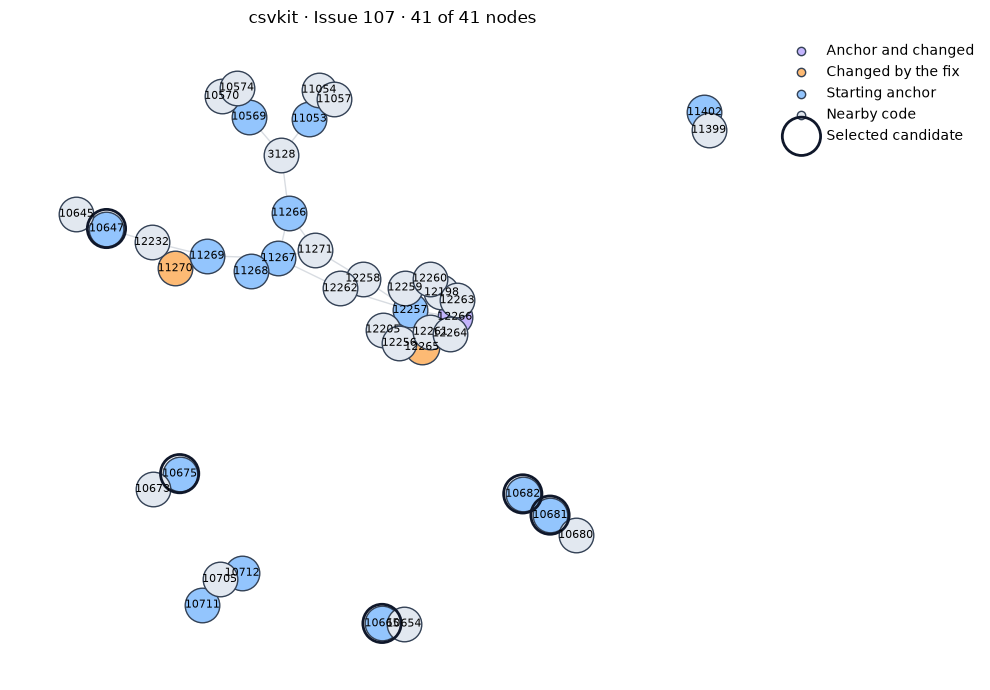

Changed nodes present in the full issue graph: 3 of 3


In [17]:
issue_network = to_networkx_issue_graph(plot_data)
plot_issue_graph(plot_issue, issue_network, selected_ids=selected_ids)

## 5. Measure where localization can fail

Imagine a bug report says that `csvkit` handles empty cells incorrectly. Which parts of the code need to change?

1. **Starting points (seeds or anchors).** GREPO provides code that its search identified as potentially relevant to the report, such as a function that reads CSV cells.
2. **Nearby code.** We look one connection away from those starting points. For example, the CSV reader might call a function that handles empty values.
3. **Candidates.** These are the classes and functions in the resulting graph that the ranker can consider. Files and directories may be in the graph too.
4. **Answer key (gold nodes).** These are the classes and functions the actual fix changed. We use them to check the candidate list after building it.

If the fix changed three functions and we found one at the starting points and two after looking nearby, **seed coverage** is **1 out of 3** and **expanded coverage** is **2 out of 3**. This issue counts as finding **at least one** changed node. **Complete coverage** requires finding the third function too. An issue with known changes and no candidates has zero expanded coverage.

### First table · Summary by repository

| Column | How to read it |
|---|---|
| `labeled_issues` | Number of issues with at least one known changed class or function. |
| `median_gold_size` | Median number of changed classes and functions per issue. A value such as 4.5 averages the two middle counts. |
| `median_candidates` | Median number of classes and functions the ranker could consider per issue after expansion. |
| `mean_seed_coverage` | Average share of changed nodes found at the starting points. |
| `mean_expanded_coverage` | Average share of changed nodes found among the candidates after expansion. |
| `unavailable_gold` | Total changed nodes unavailable in the repository graph at the time of their report. |
| `reachable_time_gold_missed` | Total changed nodes that existed in the repository graph at the time of their report but were missing from the candidates. |
| `any_gold_rate` | Share of labeled issues with at least one changed node among the candidates. |
| `complete_coverage_rate` | Share of labeled issues with every changed node among the candidates. |

Each issue has equal weight in the mean coverage columns. In the verified `csvkit` run, coverage rose from **19.2% to 53.4%** on average after expansion. The candidates contained at least one changed node for **56 of 68 issues** and every changed node for **24 of 68**. A ranker can recover the exact change set only when the candidates already contain every changed node.

### Second table · Inspect individual issues

| Column | How to read it |
|---|---|
| `repo`, `issue_id`, `time` | The repository, issue ID, and where the report falls in that repository’s history. |
| `gold_size` | Number of classes and functions the actual fix changed. |
| `graph_nodes`, `graph_edges` | Number of code nodes and connections in the smaller graph for this issue. |
| `candidates` | Number of classes and functions eligible for ranking. |
| `recovered_gold`, `missing_gold` | Count of changed nodes found among the candidates, and original IDs of the changed nodes still missing. |
| `seed_gold_coverage`, `gold_coverage` | Share of changed nodes found at the starting points and after expansion, respectively. |
| `gold_unavailable_at_issue_time` | Count of changed nodes unavailable in the repository graph when the issue was reported. |
| `live_gold_missing_from_candidates` | Count of changed nodes that existed at the time but were left out of the candidate list. |
| `any_gold_reachable`, `all_gold_reachable` | Whether at least one changed node was found and whether every changed node was found, respectively. |


In [18]:
from grepo_localization.inspection import measure_issue_coverage, summarize_coverage


def plot_coverage(labeled: pd.DataFrame) -> plt.Figure:
    """Create, but do not display, the two candidate-coverage charts.

    The input must contain `gold_size` and `gold_coverage`. Returning the
    figure keeps calculation separate from notebook display.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    labeled["gold_size"].value_counts().sort_index().plot.bar(ax=axes[0], color="#3564a6")
    axes[0].set(title="Changed classes and functions per issue", xlabel="Gold set size", ylabel="Issues")
    axes[1].hist(labeled["gold_coverage"], bins=10, range=(0, 1), color="#187f76")
    axes[1].set(title="Gold nodes found among candidates", xlabel="Fraction recovered", ylabel="Issues")
    fig.tight_layout()
    return fig

,labeled_issues,median_gold_size,median_candidates,mean_seed_coverage,mean_expanded_coverage,unavailable_gold,reachable_time_gold_missed,any_gold_rate,complete_coverage_rate
repo,,,,,,,,,
csvkit,68,4.5,50.5,0.192,0.534,0,326,0.824,0.353


,repo,issue_id,time,gold_size,graph_nodes,graph_edges,candidates,recovered_gold,missing_gold,seed_gold_coverage,gold_unavailable_at_issue_time,live_gold_missing_from_candidates,gold_coverage,any_gold_reachable,all_gold_reachable
8,csvkit,22,419,2,60,122,23,0,"[5012, 5015]",0.0,0,2,0.0,False,False
9,csvkit,28,442,11,56,130,44,0,"[3295, 4041, 4058, 4066, 4317, 4627, 5203, 529...",0.0,0,11,0.0,False,False
15,csvkit,57,673,1,166,582,141,0,[8837],0.0,0,1,0.0,False,False
16,csvkit,60,675,2,59,164,47,0,"[8505, 8813]",0.0,0,2,0.0,False,False
31,csvkit,89,755,8,68,216,61,0,"[10088, 10089, 10271, 10272, 10273, 10274, 102...",0.0,0,8,0.0,False,False
34,csvkit,92,805,4,63,178,54,0,"[11433, 11436, 11437, 11438]",0.0,0,4,0.0,False,False
41,csvkit,118,865,1,32,68,27,0,[12717],0.0,0,1,0.0,False,False
44,csvkit,126,889,2,51,140,44,0,"[13106, 13112]",0.0,0,2,0.0,False,False


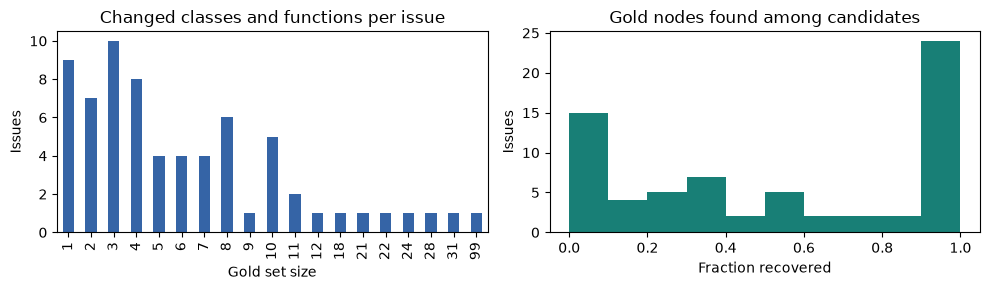

In [19]:
coverage = pd.DataFrame([
    measure_issue_coverage(issue, corpus, build_issue)
    for issue in issues.to_dict("records")
])
labeled = coverage.loc[coverage.gold_size > 0]
if labeled.empty:
    raise ValueError("No class or function gold labels in this selection. Choose another repository.")

display(summarize_coverage(labeled))
display(labeled.sort_values(["gold_coverage", "issue_id"]).head(8))
plot_coverage(labeled)
plt.show()

## 6. Create train and test datasets and check a GNN forward pass

Use a reproducible chronological 80/20 split **by distinct issue times within each repository**, keeping ties together. This is a starter protocol. The official baseline references filtered split files that were absent from the ModelScope manifest inspected for this notebook. Use the authors' split if you obtain it and want to compare paper numbers.

The PyG dataset builds issue graphs on demand. Preprocessing and the dataset stay on CPU. The smoke test moves the GraphSAGE layer and one batch to the selected device. Later training can use the candidate mask for loss and ranking. Keep all labeled test issues in the evaluation denominator, including cases with no candidates.

### Split issues and build data loaders

In [20]:
from grepo_localization.dataset import GrepoIssueDataset, chronological_split

In [21]:
split_table = chronological_split(issues)
display(split_table.groupby(["repo", "split"]).size().unstack(fill_value=0))

train_dataset = GrepoIssueDataset(split_table[split_table["split"] == "train"], build_issue)
test_dataset = GrepoIssueDataset(split_table[split_table["split"] == "test"], build_issue)
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)

split,test,train
repo,,
csvkit,13,55


### Verify a batch on the selected device

In [22]:
from grepo_localization.exploration import first_nonempty_batch, graphsage_logits

In [23]:
batch = first_nonempty_batch(train_loader)
logits = graphsage_logits(batch, device)
assert logits.shape == batch.y.shape == batch.candidate_mask.shape
print(f"GraphSAGE forward pass on {device}: {batch.num_graphs} graphs, {batch.num_nodes:,} nodes, "
      f"{int(batch.candidate_mask.sum()):,} scored candidates")

GraphSAGE forward pass on cpu: 2 graphs, 97 nodes, 80 scored candidates


## 7. Export the prepared dataset (optional)

The export stores plain tensors and primitive metadata, one file per issue, plus a split manifest. Reload each issue with `Data(**torch.load(path, weights_only=True))`. Keep the downloaded release files out of the public repository. Commit the notebook and instructions for regenerating the dataset.

In [24]:
from grepo_localization.exploration import export_issue_graphs

In [25]:
EXPORT = False
if EXPORT:
    settings = f"hops{HOPS}_{'content' if USE_CONTENT_EMBEDDINGS else 'structural'}"
    export_root = ROOT / "prepared" / settings
    datasets = {"train": train_dataset, "test": test_dataset}
    export_manifest = export_issue_graphs(datasets, coverage, export_root)
    print(f"Exported {len(export_manifest):,} issue graphs to {export_root}")

## Project Milestone 1 · Create a public repository

| Deliverable | Completion criterion |
|---|---|
| GNN-ready dataset | Document the source and regenerate issue graphs, node features, labels, and splits with the download and preprocessing notebook. |
| Notebook 1 · Dataset exploration | Show sample issues, graph sizes and relation counts, change-set sizes, and candidate coverage. |
| Notebook 2 · Train and evaluate a GNN | Train GraphSAGE or GAT for class and function localization. Compare with a feature-only MLP on the same candidate nodes, features, and splits. Report Hit@K, Recall@K, and the fraction of issues whose entire gold set appears in the top K. |
| Analysis · Why GREPO hit rates are low | Measure candidate coverage before ranking. Then measure ranking misses on issues where at least one gold node was reachable. Compare with the paper only under a matching evaluation protocol. |
| Analysis · Does graph structure help? | Compare real edges with no edges and a shuffled-edge control. Keep candidate generation fixed so the result isolates message passing. Separately compare candidate coverage before and after graph expansion. |
| Future direction | Use the results to decide whether to improve retrieval, revise graph relations, or try a set decoder. Document the representative successes and failures behind that choice. |

**Public repo contents** · README, both notebooks, reproducible environment setup, and a short results write-up.